# Advanced Active Learning with Multiple Annotators

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](<colab_link>)

> **Google Colab:** If imports fail after installation, select
> **Runtime → Restart session**, then run the notebook again.

Learn from noisy labels while choosing which annotator to ask. This example compares majority voting with random annotator selection against `AnnotMixClassifier` with learned annotator preferences on handwritten digits. Both use the same CNN backbone and random sample selection. The worked loop exposes label matrices, classifier construction, sample–annotator queries, and two accuracy denominators. Read [the multi-annotator introduction](10_multiple_annotators_getting_started.ipynb) first. The notebook assumes basic PyTorch knowledge. The comparison changes both the label model and annotator selection, so it evaluates complete workflows rather than isolating either effect.

## Setup

Uncomment the installation command if packages are missing. The digits dataset is bundled with scikit-learn. Run from a fresh kernel when changing the training configuration.

In [1]:
# !pip install "scikit-activeml[opt]" torch tqdm

### Choose the Training and Annotation Budgets

`QUICK_RUN=False` selects the reference configuration. Set it to `True` to shorten training and acquisition while retaining all images and both workflows. Their factories remain visible in `classifier_dict`, where you can comment out a workflow.

| Setting | Reference run | Quick run |
| --- | ---: | ---: |
| Repetitions per workflow | 3 | 2 |
| Acquisition batches | 10 | 3 |
| Labels per batch | 64 | 64 |
| Final acquired labels | 640 | 192 |
| Epochs per nonempty fit | 100 | 5 |
| Training DataLoader workers | 1 | 0 |

Both configurations include a zero-label checkpoint. Short training in quick execution demonstrates the workflow and need not yield a well-trained annotator model.

In [2]:
QUICK_RUN = False
USE_GPU = True

query_batch_size = 64
if QUICK_RUN:
    n_reps = 2
    n_cycles = 3
    max_epochs = 5
    loader_workers = 0
else:
    n_reps = 3
    n_cycles = 10
    max_epochs = 100
    loader_workers = 1

The query wrapper combines random sample selection with random or learned annotator preferences.

In [3]:
import logging
import warnings

logging.disable(logging.WARNING)
warnings.filterwarnings("ignore")

from copy import deepcopy
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from skorch.callbacks import LRScheduler
from torch import nn
from torch.optim import RAdam
from torch.optim.lr_scheduler import CosineAnnealingLR
from tqdm import tqdm

from skactiveml.classifier import SkorchClassifier
from skactiveml.classifier.multiannotator import AnnotMixClassifier
from skactiveml.pool import RandomSampling
from skactiveml.pool.multiannotator import SingleAnnotatorWrapper
from skactiveml.utils import MISSING_LABEL, is_labeled, majority_vote

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.labelsize": 11,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.titlesize": 12,
        "figure.titlesize": 12,
        "legend.fontsize": 10,
    }
)

DEVICE = "cuda" if USE_GPU and torch.cuda.is_available() else "cpu"

## Prepare Digits and Simulate Annotators

Scale each 8×8 grayscale image to `[0, 1]`, add its channel dimension, and use a stratified 50/50 split with seed 42. Both configurations use all 1,797 images and the known ten-class vocabulary.

| Object | Shape | Role |
| --- | --- | --- |
| `X_train` | `(898, 1, 8, 8)` | Pool images for fitting and querying. |
| `y_train` | `(898,)` | Reference classes for simulating and assessing labels. |
| `z_train` | `(898, 5)` | Complete hidden oracle, read only at queried entries. |
| `y` | `(898, 5)` | Acquired labels, initially all `MISSING_LABEL`. |
| `X_test`, `y_test` | `(899, 1, 8, 8)`, `(899,)` | Held-out data for classifier scoring. |

Five annotators supply different error patterns. For annotators 1–4, an error chooses a uniformly random class other than the reference class. Annotator 5 instead sometimes replaces the label with the most frequent training class.

| Annotator | Labeling behavior |
| --- | --- |
| 1 | Correct with probability 0.95. |
| 2 | Correct with probability 0.85. |
| 3 | Correct with probability 0.70. |
| 4 | Correct with probability 0.40 on digit 9 and 0.85 otherwise. |
| 5 | Start correct, then replace with the most frequent class with probability 0.50. |

Annotator 5 stays correct when replacement equals the reference class, so its expected accuracy exceeds 0.50. Seed 0 creates one fixed oracle table shared by all repetitions and workflows. Its realized accuracies can differ from the specified probabilities.

In [4]:
digits = load_digits()
X = (digits.images[:, np.newaxis, :, :] / 16.0).astype(np.float32)
classes = np.unique(digits.target)
X_train, X_test, y_train, y_test = train_test_split(
    X, digits.target, test_size=0.5, stratify=digits.target, random_state=42
)
rng = np.random.default_rng(0)
n_samples = len(y_train)


def sample_noisy_labels(y_true, accuracy, rng):
    """Return the true class with the given probability, else a wrong class."""
    y_annot = np.array(y_true, copy=True)
    wrong_indices = np.flatnonzero(rng.random(len(y_true)) >= accuracy)
    for index in wrong_indices:
        y_annot[index] = rng.choice(classes[classes != y_true[index]])
    return y_annot


ann1 = sample_noisy_labels(y_train, accuracy=0.95, rng=rng)
ann2 = sample_noisy_labels(y_train, accuracy=0.85, rng=rng)
ann3 = sample_noisy_labels(y_train, accuracy=0.70, rng=rng)
ann4 = sample_noisy_labels(
    y_train, accuracy=np.where(y_train == 9, 0.40, 0.85), rng=rng
)

values, counts = np.unique(y_train, return_counts=True)
majority_class = values[counts.argmax()]
ann5 = y_train.copy()
ann5[rng.random(n_samples) < 0.50] = majority_class

z_train = np.column_stack([ann1, ann2, ann3, ann4, ann5])
n_annotators = z_train.shape[1]

An acquired label is one observed matrix entry. For example, `y[12, 0] = 2` and `y[12, 3] = 7` spend two annotation requests on one image, even though the labels disagree. The oracle has 4,490 possible entries, but only acquired entries enter training. The budget therefore counts annotation requests, while the distinct-sample count measures how many images have at least one label.

## Define the Shared Classifier Backbone

Both workflows use a CNN returning digit logits and a 128-dimensional image embedding:

| Step | Shape for a batch of 16 |
| --- | --- |
| Input | `(16, 1, 8, 8)` |
| Convolution and ReLU | `(16, 8, 8, 8)` |
| Max pooling | `(16, 8, 4, 4)` |
| Flattened embedding | `(16, 128)` |
| Linear class logits | `(16, 10)` |

`MajorityVoteClassifier` reduces each row of labels to a single class before calling `SkorchClassifier.fit`. The seed fixes tie breaking, and an entirely missing row stays unlabeled. `AnnotMixClassifier` consumes the matrix directly, using annotator-specific labels to learn the class distribution and annotator behavior. [Annot-Mix](https://arxiv.org/abs/2405.03386) extends mixup to sample–annotator pairs. Its annotator model can also use the CNN embedding.

In [5]:
class CNNModule(nn.Module):
    """Return digit logits and a 128-dimensional embedding."""

    feature_dim = 128

    def __init__(self, n_classes=10):
        super().__init__()

        # Input: (B, 1, 8, 8)
        self.conv = nn.Conv2d(
            in_channels=1,
            out_channels=8,
            kernel_size=3,
            padding=1,
        )  # -> (B, 8, 8, 8)

        # Pooling leaves 8 channels with 4 × 4 values each.
        self.fc = nn.Linear(self.feature_dim, n_classes)

    def forward(self, x: torch.Tensor):
        # x: (B, 1, 8, 8)
        x = self.conv(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)  # (B, 8, 4, 4)
        x_embed = x.view(x.size(0), -1)  # (B, 128)
        logits = self.fc(x_embed)  # (B, n_classes)
        return logits, x_embed


class MajorityVoteClassifier(SkorchClassifier):
    """Train on a reproducible majority vote for each sample."""

    def fit(self, X, y, **fit_params):
        y_mv = majority_vote(
            y,
            classes=self.classes,
            missing_label=self.missing_label,
            random_state=self.random_state,
        )
        return super().fit(X, y_mv, **fit_params)

Both factories share the CNN, RAdam at learning rate 0.01 with no weight decay, training batches of 16, and prediction batches of 64. The cosine schedule spans `max_epochs`. `train_split=None` disables an internal validation split, and `drop_last=True` drops an incomplete training batch. Every `fit` starts fresh weights on the acquired labels. The held-out split is used only for scoring.

| Workflow | Training labels | Sample selection | Annotator selection |
| --- | --- | --- | --- |
| `Majority-Vote` | Majority-vote class per observed row | Random | Random, with `A_perf=None` |
| `Annot-Mix` | Label matrix and learned annotator model | Random | Initially random, then learned correctness preferences |

`sample_embed_dim=2` adds a learned two-dimensional representation to Annot-Mix's annotator model. The CNN still produces its 128-dimensional embedding. Deep-copied settings give every run independent classifiers and callbacks.

In [6]:
# Training settings shared by both methods.
neural_net_param_dict = {
    # Module-related parameters.
    "module__n_classes": len(classes),
    # Optimizer-related parameters.
    "max_epochs": max_epochs,
    "optimizer": RAdam,
    "optimizer__weight_decay": 0.0,
    "optimizer__lr": 0.01,
    # Data loading parameters.
    "iterator_train__shuffle": True,
    "iterator_train__num_workers": loader_workers,
    "iterator_train__batch_size": 16,
    "iterator_valid__batch_size": 64,
    "iterator_train__drop_last": True,
    "train_split": None,
    # Scheduler.
    "callbacks": [
        (
            "lr_scheduler",
            LRScheduler(policy=CosineAnnealingLR, T_max=max_epochs),
        ),
    ],
    "warm_start": False,
    "verbose": 0,
    "device": DEVICE,
}

# Common keyword arguments shared by all classifiers
common_clf_kwargs = dict(
    classes=classes,
    missing_label=MISSING_LABEL,
    sample_dtype=np.float32,
    neural_net_param_dict=neural_net_param_dict,
)


def make_majority_vote_classifier(random_state):
    return MajorityVoteClassifier(
        module=CNNModule,
        criterion=nn.CrossEntropyLoss,
        random_state=random_state,
        **deepcopy(common_clf_kwargs),
    )


def make_annot_mix_classifier(random_state):
    return AnnotMixClassifier(
        clf_module=CNNModule,
        sample_embed_dim=2,
        n_annotators=n_annotators,
        random_state=random_state,
        **deepcopy(common_clf_kwargs),
    )


classifier_dict = {
    "Majority-Vote": make_majority_vote_classifier,
    "Annot-Mix": make_annot_mix_classifier,
}

## Run Paired Repetitions

Each repetition starts with an all-missing label matrix. Matching seeds pair the classifier setup and the initial random query. Later models and annotator choices can diverge. Data and oracle labels stay fixed, so repetition variation describes the learning procedure on this one simulated dataset.

At each checkpoint, fit the acquired labels and score held-out digits. If another acquisition remains, request sample–annotator pairs and reveal exactly their oracle entries. Pair `[12, 3]` assigns `z_train[12, 3]` to `y[12, 3]`. `n_annotators_per_sample=1` requests one annotator for each selected image within a batch. Images can receive additional labels in later batches.

After a nonempty fit, Annot-Mix returns `A_perf` with shape `(n_samples, n_annotators)`. Entry `[i, a]` estimates the probability that annotator `a` labels sample `i` correctly. The wrapper prefers larger values among annotators with an available label. These are learned estimates, rather than oracle accuracies. The first query uses `A_perf=None` because no labels have trained the model. Majority-Vote keeps it `None` throughout.

The two reported accuracies have different denominators. For observed entries $\mathcal{O}$:

$$\operatorname{Acc}_{\mathrm{test}}=\frac{1}{n_{\mathrm{test}}}\sum_{i=1}^{n_{\mathrm{test}}}\mathbf{1}[\hat y_i=y_{\mathrm{test},i}],$$

$$\operatorname{Acc}_{\mathrm{annotation}}=\frac{1}{|\mathcal{O}|}\sum_{(i,a)\in\mathcal{O}}\mathbf{1}[y_{i,a}=y_{\mathrm{train},i}].$$

Three labels `[2, 2, 7]` for an image of class 2 give annotation accuracy 2/3, although their majority vote is correct. At zero labels, initialized networks give a test baseline, and annotation accuracy is `NaN` because its denominator is zero. The final batch is fitted and scored, with no extra query after the last checkpoint. Each saved array has shape `(n_reps, n_cycles + 1)`.

In [7]:
results = {}

for clf_name, clf_factory in classifier_dict.items():
    clf_acc = np.full((n_reps, n_cycles + 1), np.nan)
    label_acc = np.full_like(clf_acc, np.nan)
    annotation_counts = np.zeros_like(clf_acc, dtype=int)
    sample_counts = np.zeros_like(clf_acc, dtype=int)

    for i_rep in range(n_reps):
        torch.manual_seed(i_rep)
        y = np.full(z_train.shape, MISSING_LABEL, dtype=np.float32)
        clf = clf_factory(random_state=i_rep)
        ma_qs = SingleAnnotatorWrapper(
            RandomSampling(random_state=i_rep), random_state=i_rep
        )

        for cycle in tqdm(
            range(n_cycles + 1),
            desc=f"{clf_name} | repetition {i_rep + 1}/{n_reps}",
            file=sys.stdout,
            ascii=True,
            ncols=88,
            mininterval=20,
            leave=True,
        ):
            clf.fit(X_train, y)

            observed = is_labeled(y)
            n_annotations = int(observed.sum())
            annotation_counts[i_rep, cycle] = n_annotations
            sample_counts[i_rep, cycle] = observed.any(axis=1).sum()
            clf_acc[i_rep, cycle] = clf.score(X_test, y_test)
            if n_annotations:
                label_acc[i_rep, cycle] = np.mean(
                    (y == y_train[:, None])[observed]
                )

            if cycle < n_cycles:
                A_perf = None
                if clf_name == "Annot-Mix" and n_annotations:
                    _, A_perf = clf.predict_proba(
                        X_train, extra_outputs=["annotator_perf"]
                    )
                query_idx = ma_qs.query(
                    X=X_train,
                    y=y,
                    batch_size=query_batch_size,
                    A_perf=A_perf,
                    n_annotators_per_sample=1,
                )
                sample_idx, annotator_idx = query_idx.T
                y[sample_idx, annotator_idx] = z_train[
                    sample_idx, annotator_idx
                ]

    results[clf_name] = {
        "clf-acc": clf_acc,
        "label-acc": label_acc,
        "annotation_counts": annotation_counts,
        "sample_counts": sample_counts,
    }

Majority-Vote | repetition 1/3: 100%|###################| 11/11 [00:49<00:00,  4.53s/it]
Majority-Vote | repetition 2/3: 100%|###################| 11/11 [00:48<00:00,  4.43s/it]
Majority-Vote | repetition 3/3: 100%|###################| 11/11 [00:48<00:00,  4.42s/it]
Annot-Mix | repetition 1/3: 100%|#######################| 11/11 [01:10<00:00,  6.43s/it]
Annot-Mix | repetition 2/3: 100%|#######################| 11/11 [01:10<00:00,  6.43s/it]
Annot-Mix | repetition 3/3: 100%|#######################| 11/11 [01:10<00:00,  6.38s/it]


## Compare Classifier and Annotation Accuracy

The upper panel measures held-out digit classification. The lower panel
measures acquired labels against reference classes before aggregation,
starting at 64 labels because the initial value is undefined.
Both horizontal axes count acquired labels.

Lines average repetitions, and light bands show one sample standard deviation
(`ddof=1`). Legend values average the evaluated budgets, including the initial
test baseline and excluding undefined annotation accuracy. More accurate
labels can help fitting, but test accuracy also depends on the selected
images and the label model.

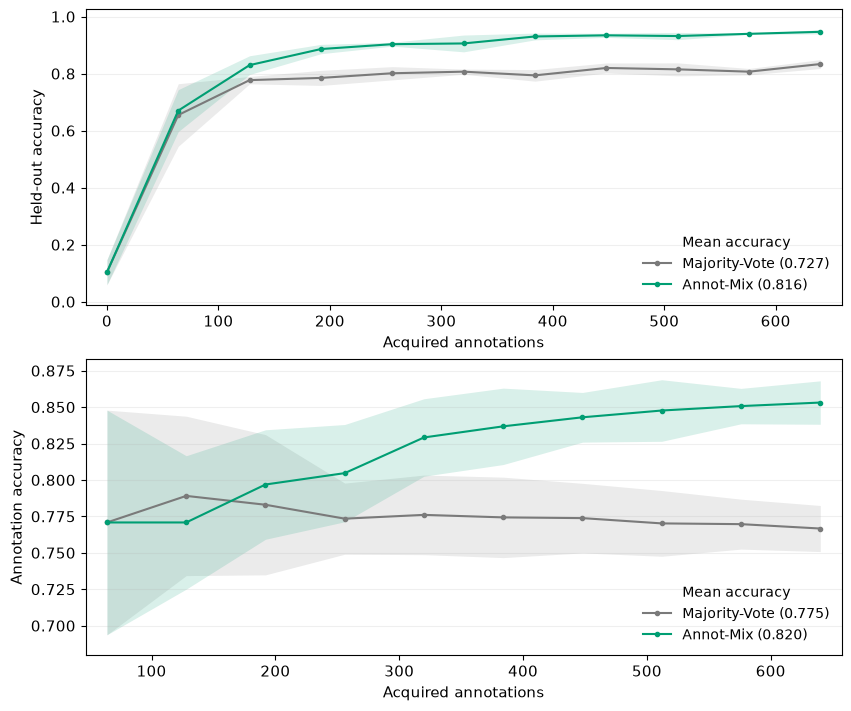

In [8]:
workflow_colors = {"Majority-Vote": "#7A7A7A", "Annot-Mix": "#009E73"}
fig, axes = plt.subplots(2, 1, figsize=(8.4, 7.0), constrained_layout=True)
metrics = [
    ("clf-acc", "Held-out accuracy"),
    ("label-acc", "Annotation accuracy"),
]

for (metric_key, ylabel), ax in zip(metrics, axes):
    for clf_name, result in results.items():
        scores = result[metric_key]
        valid = np.isfinite(scores).any(axis=0)
        # Every repetition requests the same number of pairs per cycle.
        budgets = result["annotation_counts"][0, valid]
        mean_curve = scores[:, valid].mean(axis=0)
        std_curve = scores[:, valid].std(axis=0, ddof=1)
        ax.plot(
            budgets,
            mean_curve,
            color=workflow_colors[clf_name],
            marker="o",
            markersize=3,
            label=f"{clf_name} ({mean_curve.mean():.3f})",
        )
        ax.fill_between(
            budgets,
            np.clip(mean_curve - std_curve, 0, 1),
            np.clip(mean_curve + std_curve, 0, 1),
            color=workflow_colors[clf_name],
            alpha=0.15,
            linewidth=0,
        )
    ax.set(xlabel="Acquired annotations", ylabel=ylabel)
    ax.margins(x=0.03, y=0.08)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(loc="lower right", title="Mean accuracy", frameon=False)
plt.show()

## Adapt the Workflows

Both configurations use one split and one simulated oracle. Three reference repetitions describe seed variation, rather than variation across annotator populations or datasets. [The evaluation tutorial](04_pool_simple_evaluation_study.ipynb) explains how to broaden comparisons.

To separate the two changes in this experiment, set `A_perf=None` for both workflows when comparing their label models. Then keep Annot-Mix fixed and compare random with learned annotator preferences. Varying error patterns or `n_annotators_per_sample` can test the tradeoff between annotating more images and collecting multiple labels per image. Keep acquired-label budgets equal, track distinct images, and report both accuracies.